<a href="https://colab.research.google.com/github/annkupina/bank_marketing_project/blob/main/bank_marketing_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Імпорт бібліотек

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report, average_precision_score, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
import xgboost as xgb
from hyperopt import hp, fmin, tpe, Trials, STATUS_OK
from sklearn.model_selection import cross_val_score, RandomizedSearchCV, TimeSeriesSplit, GridSearchCV, StratifiedKFold
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from imblearn.under_sampling import RandomUnderSampler
import lightgbm as lgb
from scipy.stats import randint, uniform
from sklearn.ensemble import VotingClassifier
import shap

##Імпорт і загальний огляд даних

In [2]:
raw_data = pd.read_csv('bank-additional-full.csv',sep=';')
raw_data.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
raw_data.duplicated().sum()

np.int64(12)

Маємо 12 дублікатів, видаляємо їх.

In [4]:
raw_data = raw_data.drop_duplicates().reset_index(drop=True)

In [5]:
raw_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41176 entries, 0 to 41175
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41176 non-null  int64  
 1   job             41176 non-null  object 
 2   marital         41176 non-null  object 
 3   education       41176 non-null  object 
 4   default         41176 non-null  object 
 5   housing         41176 non-null  object 
 6   loan            41176 non-null  object 
 7   contact         41176 non-null  object 
 8   month           41176 non-null  object 
 9   day_of_week     41176 non-null  object 
 10  duration        41176 non-null  int64  
 11  campaign        41176 non-null  int64  
 12  pdays           41176 non-null  int64  
 13  previous        41176 non-null  int64  
 14  poutcome        41176 non-null  object 
 15  emp.var.rate    41176 non-null  float64
 16  cons.price.idx  41176 non-null  float64
 17  cons.conf.idx   41176 non-null 

Датасет має 41176 рядків та 21 колонку.

Пропущених значень немає.

##EDA

### Перевірка дисбалансу для цільового стовпця y

In [6]:
raw_data['y'] = raw_data['y'].map({'yes': 1, 'no': 0})

In [7]:
raw_data['y'].value_counts().sort_values(ascending = False)

,count
y,
0,36537
1,4639


In [8]:
round(raw_data['y'].value_counts(normalize = True).sort_values(ascending = False) * 100, 2)

,proportion
y,
0,88.73
1,11.27


Присутній суттєвий дисбаланс класів цільової ознаки y.

Значення `y` 1 - клієнт, який підписав строковий депозит. 11,27% даних

Значення `y` 0 - клієнт, який не підписав строковий депозит. 88,73% даних

### Розподіл даних на основі цільвої ознаки y

In [9]:
df0 = raw_data[raw_data['y'] == 0]
df1 = raw_data[raw_data['y'] == 1]

### Аналіз категоріальних змінних

In [10]:
raw_data.select_dtypes(include = "object").head()

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome
0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,nonexistent
1,services,married,high.school,unknown,no,no,telephone,may,mon,nonexistent
2,services,married,high.school,no,yes,no,telephone,may,mon,nonexistent
3,admin.,married,basic.6y,no,no,no,telephone,may,mon,nonexistent
4,services,married,high.school,no,no,yes,telephone,may,mon,nonexistent


In [11]:
len(raw_data.select_dtypes(include = "object").columns)

10

Датасет містить 11 категоріальних ознак.

In [12]:
def bi_cat_countplot(df, column, hue_column):
    unique_hue_values = df[hue_column].unique()
    fig, axes = plt.subplots(nrows=1, ncols=2)
    fig.set_size_inches(14,6)

    pltname = f'Нормалізований розподіл значень за категорією: {column}'
    proportions = df.groupby(hue_column)[column].value_counts(normalize=True)
    proportions = (proportions*100).round(2)
    ax = proportions.unstack(hue_column).sort_values(
        by=unique_hue_values[0], ascending=False
        ).plot.bar(ax=axes[0], title=pltname)

    for container in ax.containers:
        ax.bar_label(container, fmt='{:,.1f}%')

    pltname = f'Кількість даних за категорією: {column}'
    counts = df.groupby(hue_column)[column].value_counts()
    ax = counts.unstack(hue_column).sort_values(
        by=unique_hue_values[0], ascending=False
        ).plot.bar(ax=axes[1], title=pltname)

    for container in ax.containers:
      ax.bar_label(container)


def uni_cat_target_compare(df, column):
    bi_cat_countplot(df, column, hue_column='y' )


def bi_countplot_target(df0, df1, column, hue_column):
  pltname = 'Клієнт, який підписав строковий депозит'
  print(pltname.upper())
  bi_cat_countplot(df1, column, hue_column)
  plt.show()

  pltname = 'Клієнти, який не підписав строковий депозит'
  print(pltname.upper())
  bi_cat_countplot(df0, column, hue_column)
  plt.show()

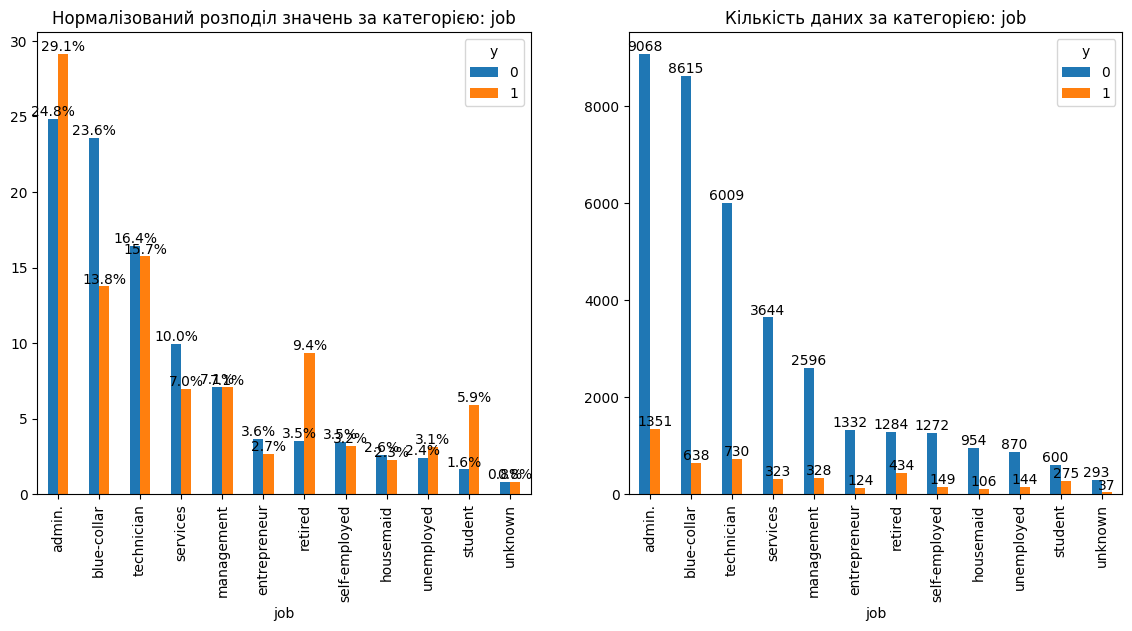

In [13]:
uni_cat_target_compare(raw_data, 'job')

На графіку бачимо помітні відмінності між клієнтами за ознакою `job` для деяких категорій.

В категоріях `admin`, `retired` та `student` більше клієнтів, які підписали строковий депозит, в категоріях `blue-collar` та `services` - навпаки.

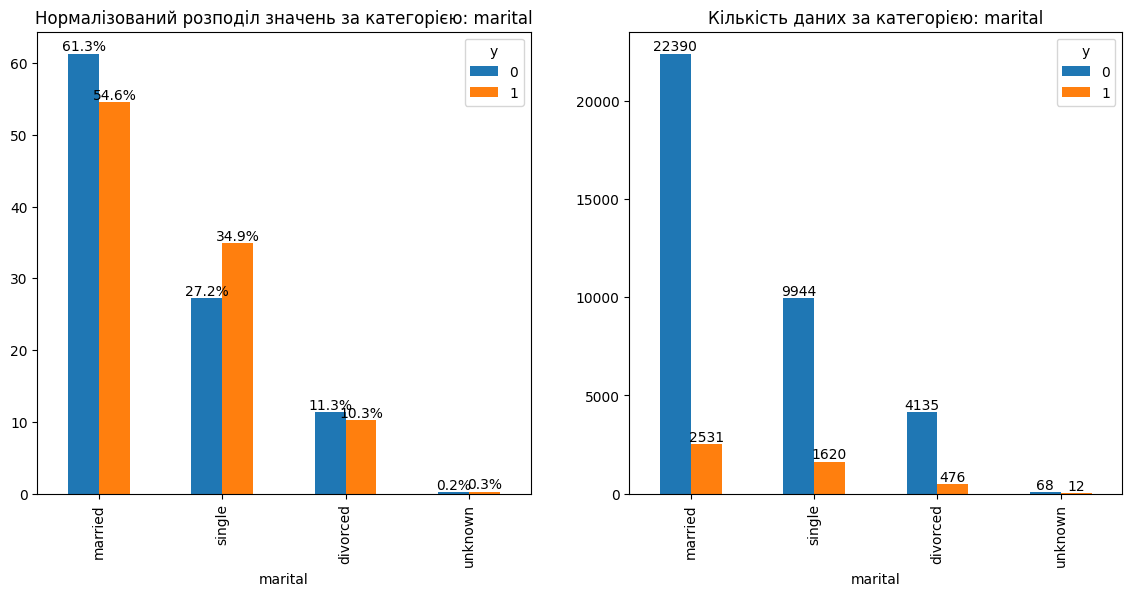

In [14]:
uni_cat_target_compare(raw_data, 'marital')

На графіку бачимо помітні відмінності між клієнтами за ознакою `marital` для категорій `married` та `single`.

В категорії `single` більше клієнтів, які підписали строковий депозит, в категорії `married` - навпаки.

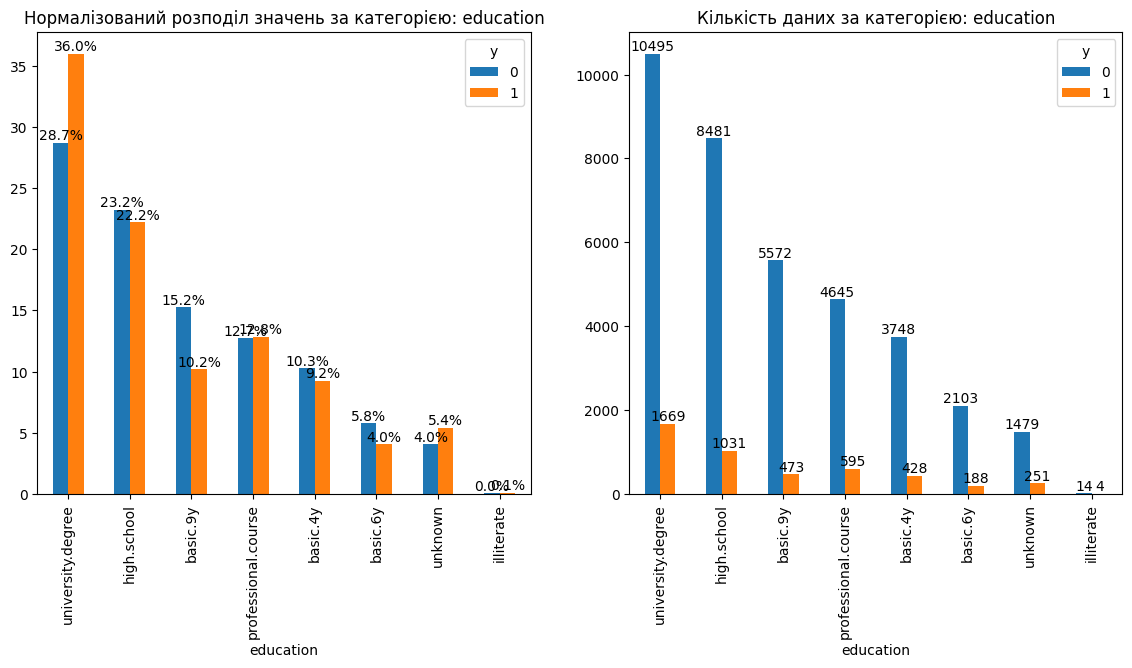

In [15]:
uni_cat_target_compare(raw_data, 'education')

Згідно графіку помітні відмінності між клієнтами за ознакою `education` для категорій `university.degree` та `basic.9y`.

В категорії `university.degree` більше клієнтів, які підписали строковий депозит, в категорії `basic.9y` більше клієнтів, які не підписали.

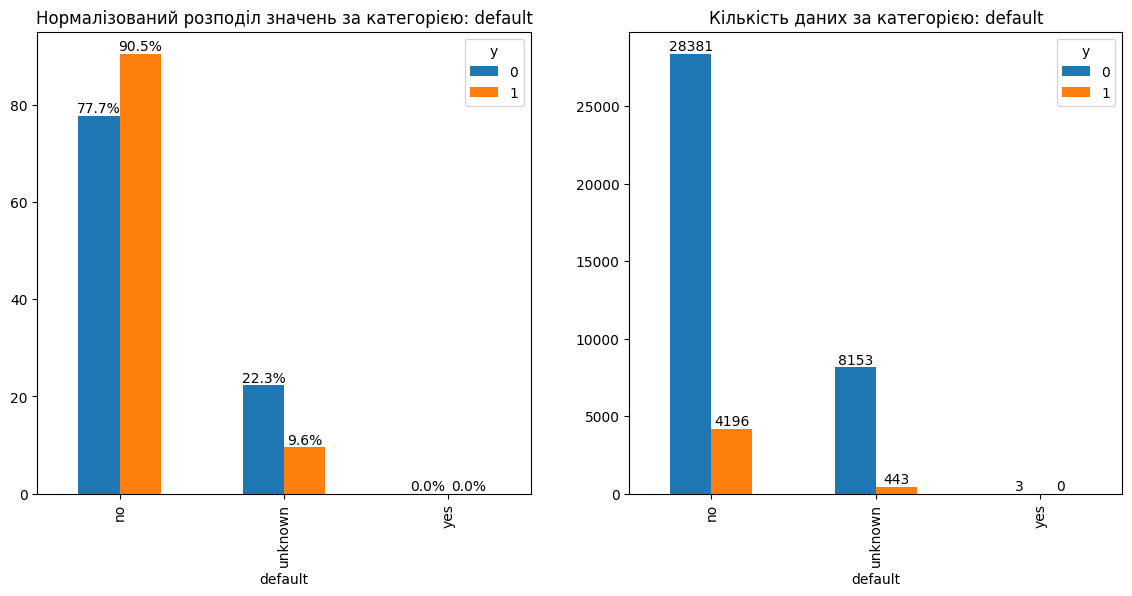

In [16]:
uni_cat_target_compare(raw_data, 'default')

На цьому графіку бачимо що є відмінності між клієнтами для колонки `default` за категоріями `no` та `unknown`.

В категорії `no`, тобто серед тих клієнтів, в яких немає просроченого кредиту, більшість тих, хто підписав строковий депозит, в категорії `unknown` - навпаки.

В категорії `yes` маємо всього тількі 3 клієнта і які не підписали строковий депозит.

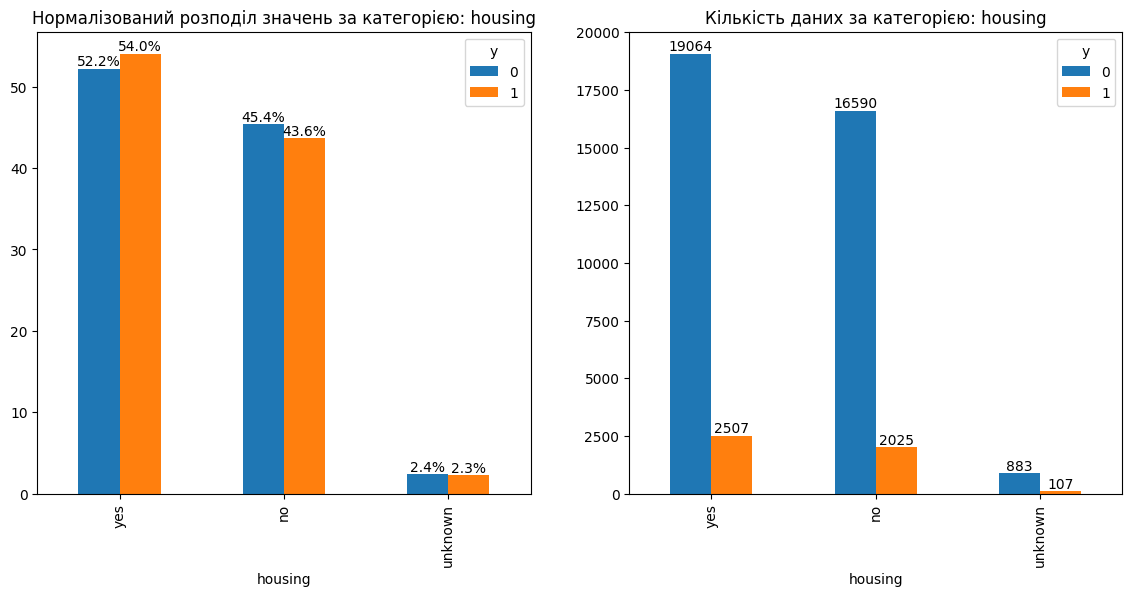

In [17]:
uni_cat_target_compare(raw_data, 'housing')

Згідно цим гістограмам немає суттєвих відмінностей у категорії  `housing` між клієнтами, які підписали і не підписали строковий депозит.

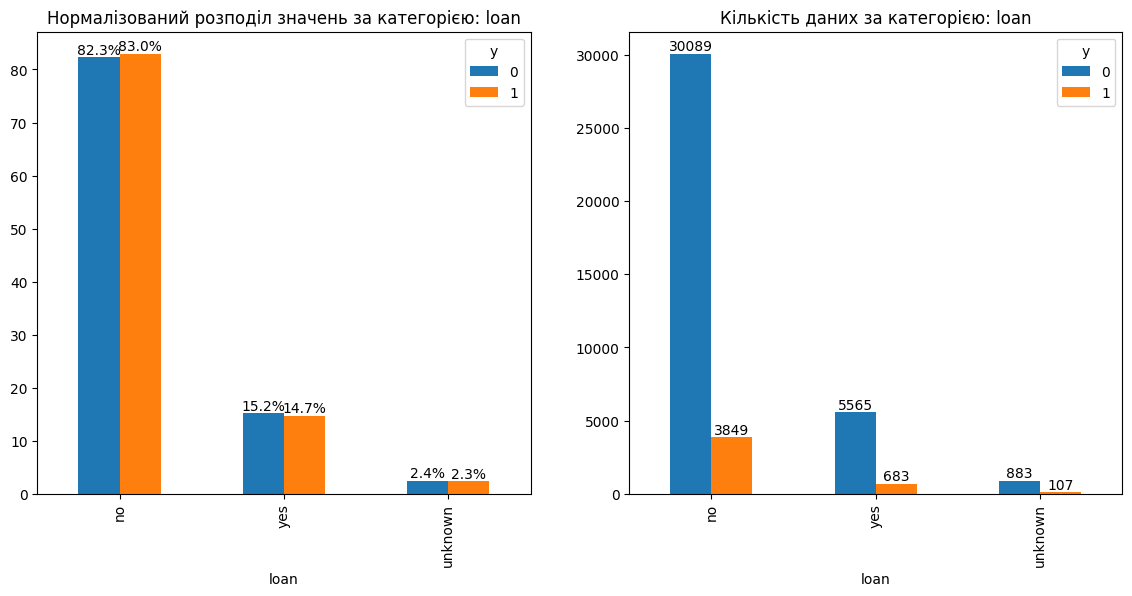

In [18]:
uni_cat_target_compare(raw_data, 'loan')

Згідно цим гістограмам немає суттєвих відмінностей у категорії  `loan` між клієнтами, які підписали і не підписали строковий депозит.

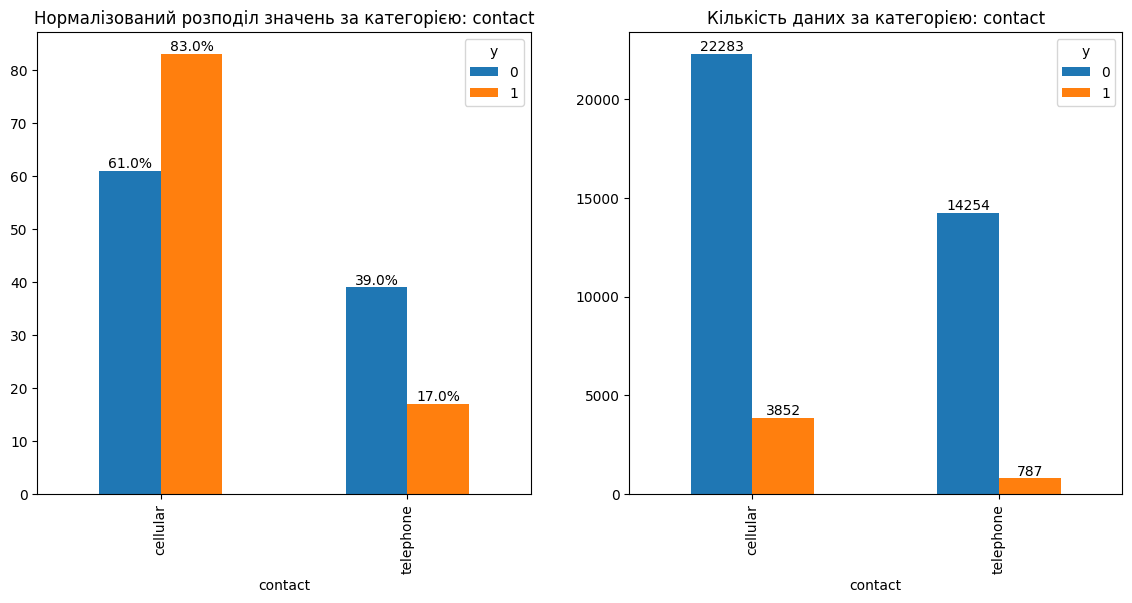

In [19]:
uni_cat_target_compare(raw_data, 'contact')

На цьому графіку бачимо що є відмінності між клієнтами для колонки `contact`.

В категорії `cellular` більшість тих клієнтів, які підписали строковий депозит, в категорії `telephone` - навпаки.

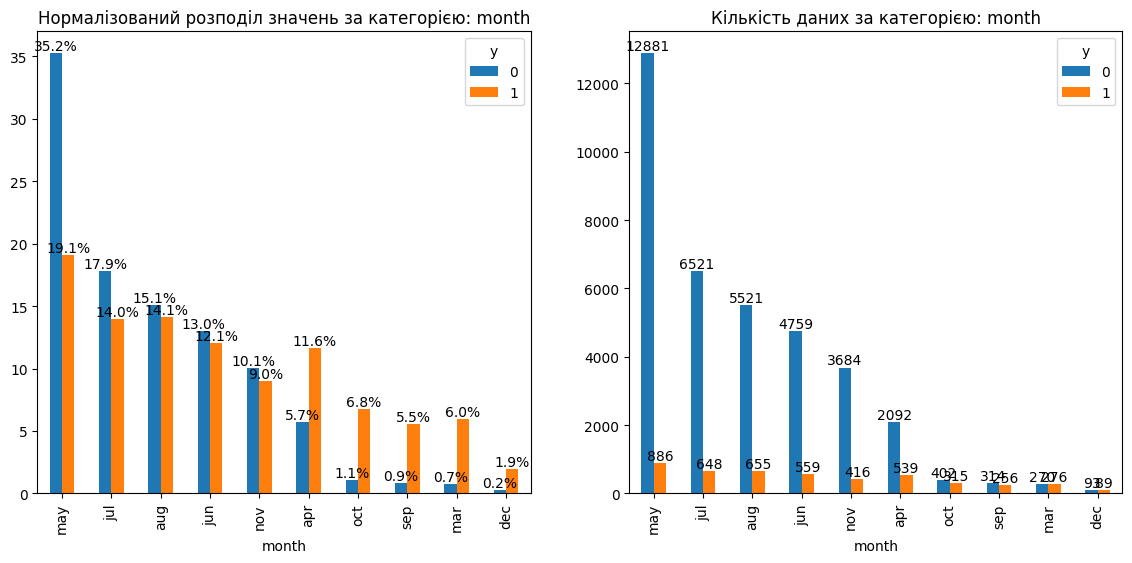

In [20]:
uni_cat_target_compare(raw_data, 'month')

На гістограмах бачимо суттєві відмінності між клієнтами за ознакою `month` в категорії `may`.

У травні місяці більшість клієнтів не підписало строковий депозит.

Трохи менша різниця, але все ж таки помітна в місяцях з квітня по березень включно, в ці місяці більше клієнтів, які підписали депозит.

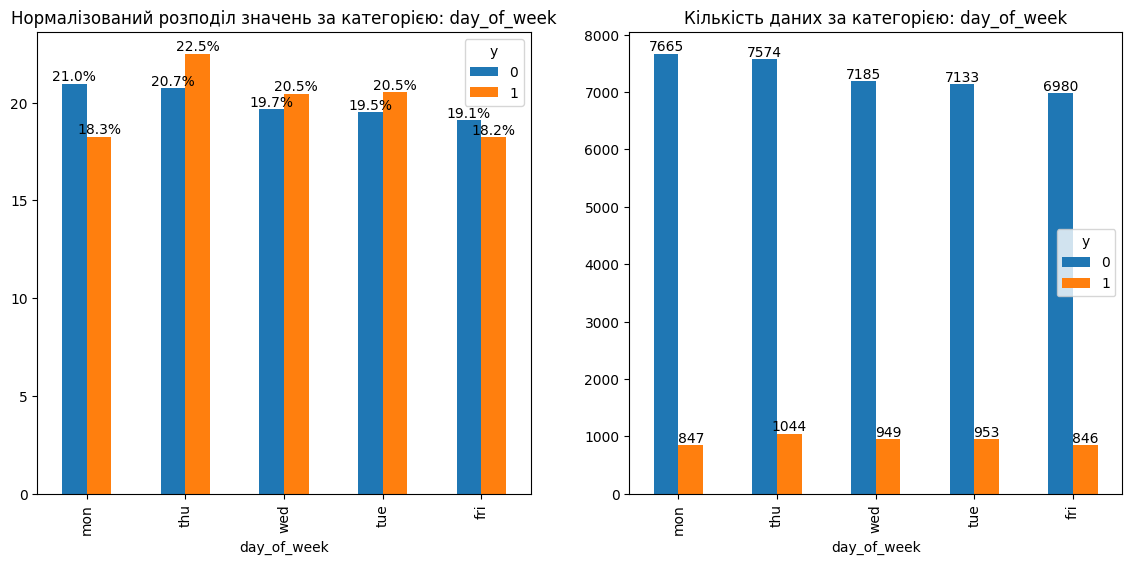

In [21]:
uni_cat_target_compare(raw_data, 'day_of_week')

Згідно графікам немає суттєвої різниці між клієнтами за ознакою `day_of_week`.

Але можемо помітити, що на початку тижня трохи переважають клієнті, які не підписали депозит.

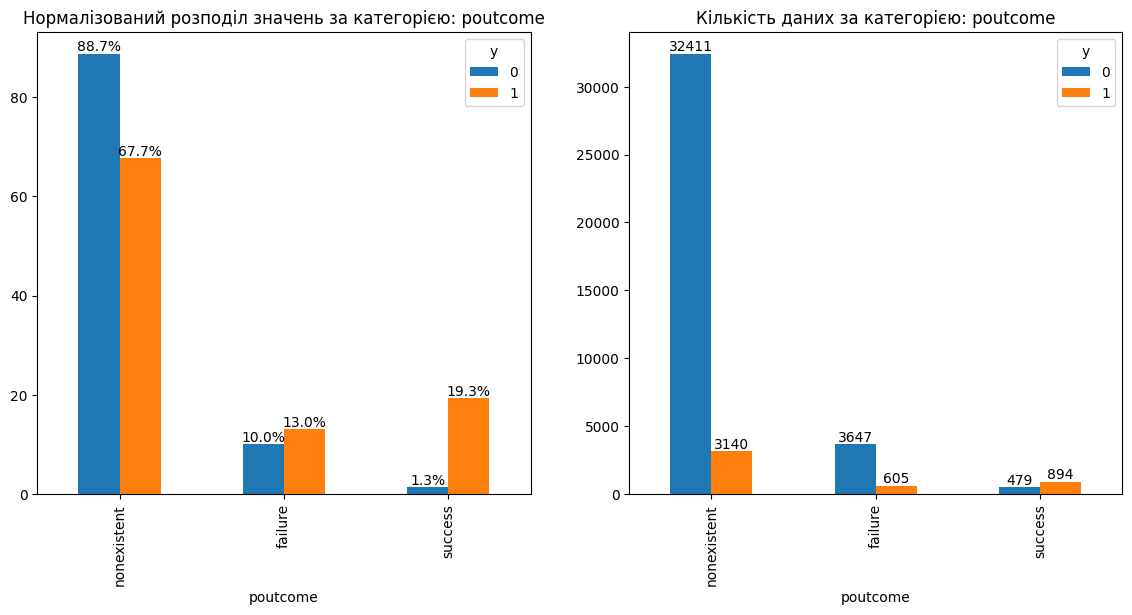

In [22]:
uni_cat_target_compare(raw_data, 'poutcome')

На цьому графіку бачимо що є суттєві відмінності між клієнтами для колонки `poutcome` за категоріями `nonexistent` та `success`.

В категорії `success` більшість тих клієнтів, які підписали строковий депозит, в категорії `nonexistent` - навпаки.

В категорії `failure` немає суттєвої відмінності.

### Аналіз числових змінних

In [23]:
raw_data.select_dtypes(include = "number").head()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,261,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0
1,57,149,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0
2,37,226,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0
3,40,151,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0
4,56,307,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0


In [24]:
len(raw_data.select_dtypes(include = "number").columns)

11

Датасет містить 11 числових змінних.

In [25]:
numeric_cols = raw_data.select_dtypes(include='number').columns

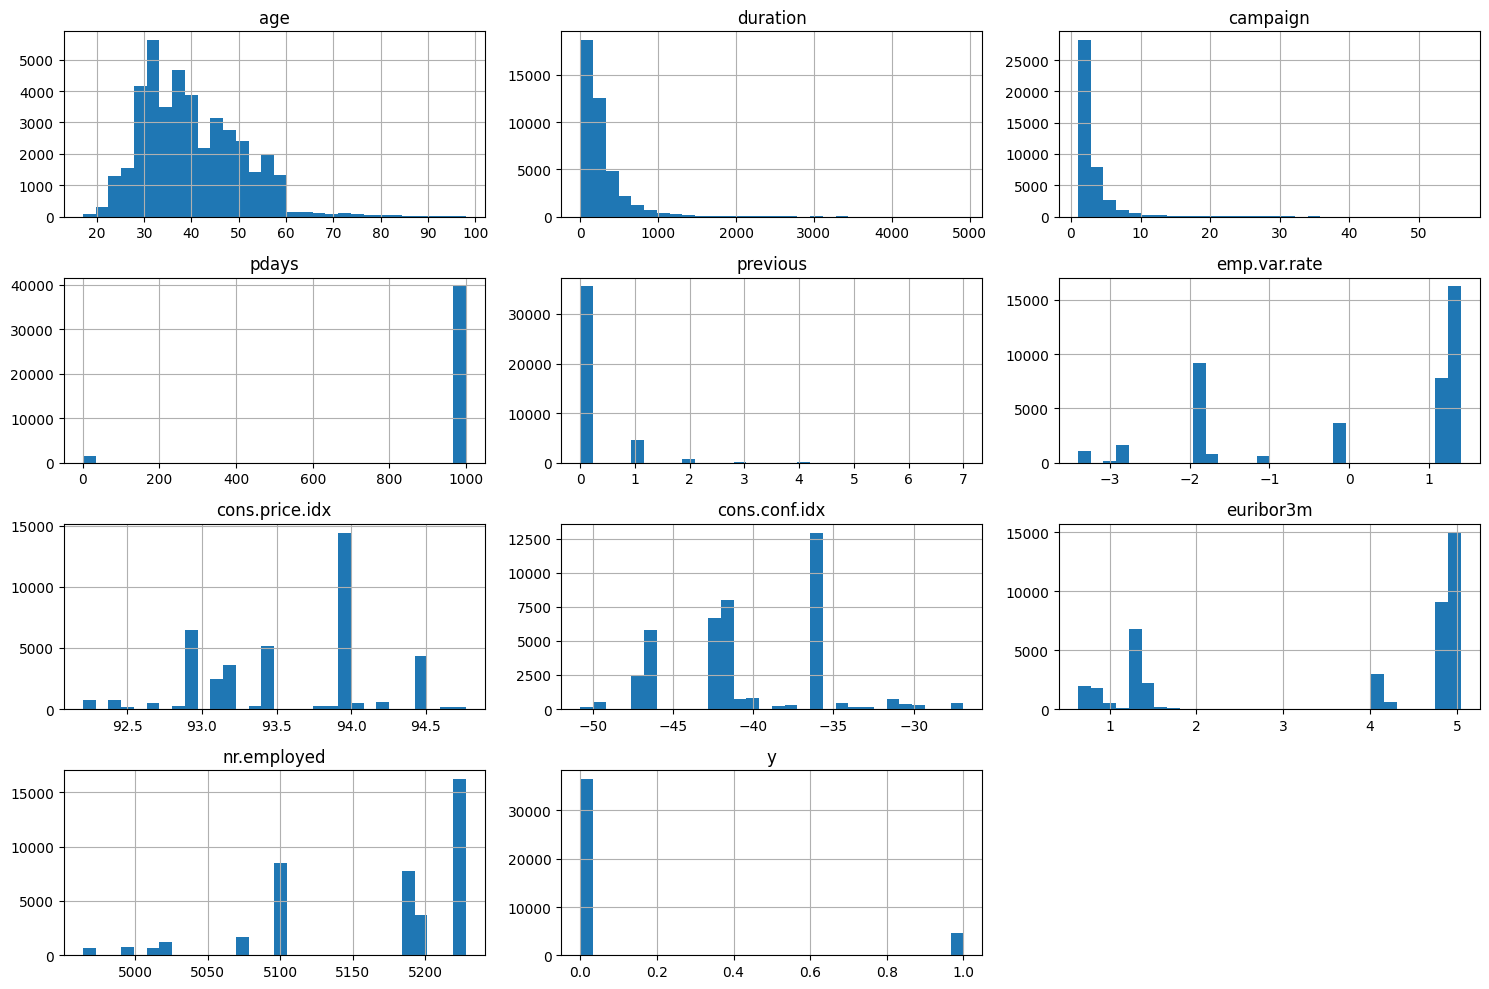

In [26]:
raw_data[numeric_cols].hist(figsize=(15, 10), bins=30)
plt.tight_layout()
plt.show()

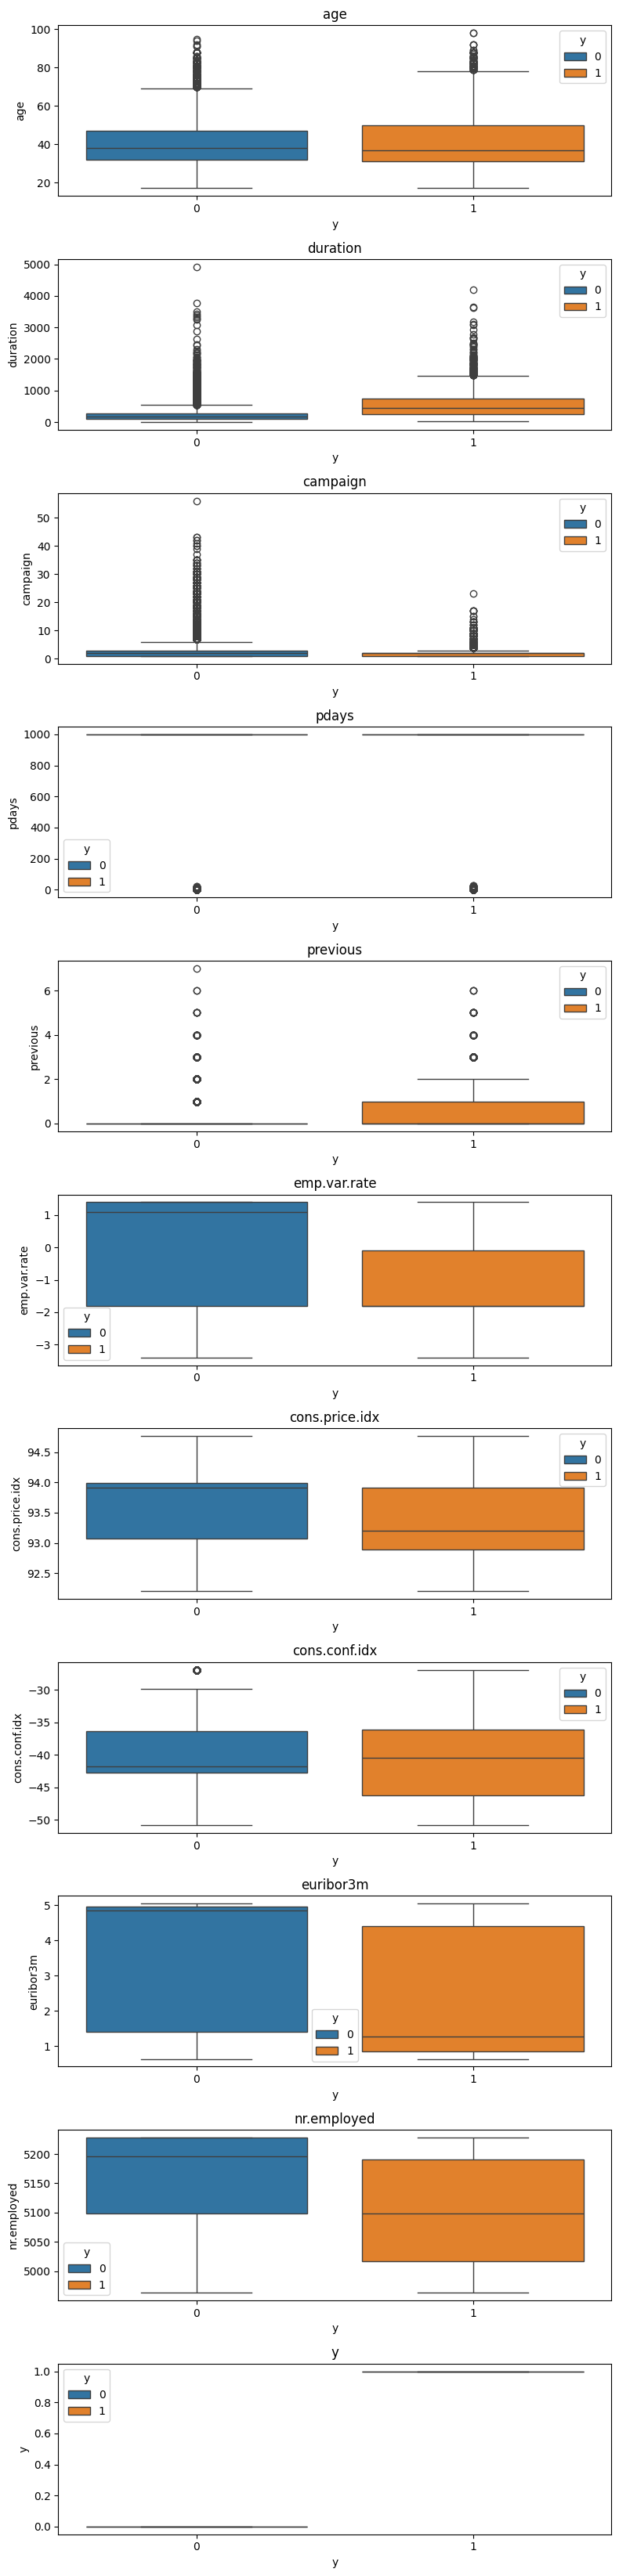

In [27]:
fig, axes = plt.subplots(len(numeric_cols), 1, figsize=(8, 3*len(numeric_cols)))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(data=raw_data, x='y', y=col, ax=ax, hue = 'y')
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [28]:
raw_data.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
count,41176.00000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000
mean,40.02380,258.315815,2.567879,962.464810,0.173013,0.081922,93.575720,-40.502863,3.621293,5167.034870,0.112663
std,10.42068,259.305321,2.770318,186.937102,0.494964,1.570883,0.578839,4.627860,1.734437,72.251364,0.316184
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000,0.000000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000,0.000000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000,0.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000,0.000000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000,1.000000


In [29]:
corr_df1 = df1.select_dtypes(include=["int64","float64"]).corr()

In [30]:
corr_df1.head()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
age,1.000000,-0.059275,-0.007881,-0.065026,0.074976,-0.081524,-0.024616,0.141119,-0.085368,-0.111960,NaN
duration,-0.059275,1.000000,0.156773,0.237962,-0.231642,0.502978,0.237405,-0.143688,0.499662,0.481978,NaN
campaign,-0.007881,0.156773,1.000000,0.106839,-0.104179,0.221655,0.116359,-0.042727,0.211798,0.202657,NaN
pdays,-0.065026,0.237962,0.106839,1.000000,-0.728936,0.280824,-0.054930,-0.170018,0.364626,0.453373,NaN
previous,0.074976,-0.231642,-0.104179,-0.728936,1.000000,-0.284923,0.091074,0.127976,-0.392096,-0.488371,NaN


In [31]:
corr_df1[corr_df1 <= 0.99].unstack().sort_values(ascending = False).head(14)

,,0
euribor3m,emp.var.rate,0.926125
emp.var.rate,euribor3m,0.926125
nr.employed,euribor3m,0.922227
euribor3m,nr.employed,0.922227
emp.var.rate,nr.employed,0.787679
nr.employed,emp.var.rate,0.787679
cons.price.idx,emp.var.rate,0.660248
emp.var.rate,cons.price.idx,0.660248
duration,emp.var.rate,0.502978
emp.var.rate,duration,0.502978


Клієнти, які підписали депозит (y=1) — найсильніші кореляції:

`euribor3m`	- `emp.var.rate` - 0.926

`nr.employed` - `euribor3m` - 0.922

`emp.var.rate` -	`nr.employed` -	0.787

`cons.price.idx` - 	`emp.var.rate` -	0.660

In [32]:
corr_df0 = df0.select_dtypes(include=["int64","float64"]).corr()

In [33]:
corr_df0[corr_df0 <= 0.99].unstack().sort_values(ascending = False).head(10)

,,0
euribor3m,emp.var.rate,0.975955
emp.var.rate,euribor3m,0.975955
nr.employed,euribor3m,0.947243
euribor3m,nr.employed,0.947243
emp.var.rate,nr.employed,0.921746
nr.employed,emp.var.rate,0.921746
cons.price.idx,emp.var.rate,0.797157
emp.var.rate,cons.price.idx,0.797157
euribor3m,cons.price.idx,0.730751
cons.price.idx,euribor3m,0.730751


Клієнти, які не підписали депозит (y=0) — найсильніші кореляції:

`euribor3m`	- `emp.var.rate` - 0.975

`nr.employed` - `euribor3m` - 0.947

`emp.var.rate` - `nr.employed` -	0.921

`cons.price.idx` - `emp.var.rate` -	0.797

`euribor3m` -	`cons.price.idx` -	0.730

`nr.employed` -	`cons.price.idx` -	0.593

Макроекономічні ознаки сильно корелюють між собою. Чи залишати їх всіх, чи обрати одну буде зрозуміло на етапі тренування моделей.

In [34]:
def outliers_summary(df, columns, target='y'):
    rows = []
    for col in columns:
        q1, q3 = df[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        mask = (df[col] < lower) | (df[col] > upper)

        bounds = []
        if (df[col] < lower).any():
            bounds.append(f'< {lower:g}')
        if (df[col] > upper).any():
            bounds.append(f'> {upper:g}')

        rows.append({
            'Ознака': f"{col} ({', '.join(bounds)})",
            'Викидів': f"{mask.sum():,} ({mask.mean():.1%})".replace(',', ' '),
            'Частка підписань у викидах': f"{df.loc[mask, target].mean():.1%}",
            'В інших': f"{df.loc[~mask, target].mean():.1%}",
        })
    return pd.DataFrame(rows)

outliers_table = outliers_summary(raw_data, ['age', 'campaign', 'pdays', 'previous', 'cons.conf.idx', 'emp.var.rate', 'cons.price.idx', 'euribor3m', 'nr.employed'])
outliers_table.style.hide(axis='index')

Ознака,Викидів,Частка підписань у викидах,В інших
age (> 69.5),468 (1.1%),47.2%,10.9%
campaign (> 6),2 406 (5.8%),4.6%,11.7%
pdays (< 999),1 515 (3.7%),63.8%,9.3%
previous (> 0),5 625 (13.7%),26.6%,8.8%
cons.conf.idx (> -26.95),446 (1.1%),40.4%,10.9%
emp.var.rate (),0 (0.0%),nan%,11.3%
cons.price.idx (),0 (0.0%),nan%,11.3%
euribor3m (),0 (0.0%),nan%,11.3%
nr.employed (),0 (0.0%),nan%,11.3%


In [35]:
raw_data[['age', 'campaign', 'cons.conf.idx']].max()

,0
age,98.0
campaign,56.0
cons.conf.idx,-26.9


Викиди за правилом IQR виявлено в 5 ознаках: `age`, `campaign`, `pdays`, `previous`, `cons.conf.idx`. Макроекономічні ознаки (`emp.var.rate`, `cons.price.idx`, `euribor3m`, `nr.employed`) викидів не мають.

Ознаки `pdays`, `previous` не виглядають як викиди. `pdays`= 999 означає відсутність контакту, а не реальне число і буде оброблено в подальшому.
`previous`> 0 означає, що викидом є будь-який попередній контакт. Але це окрема група клієнтів, а не екстремальні значення.

Стосовно ознак `age`, `campaign`, `cons.conf.idx`:

- клієнти старші за 69.5 років підписують депозит у 4 рази частіше (47.2% проти 10.9%);
- клієнти, яким телефонували понад 6 разів, підписують у 2.5 раза рідше (4.6% проти 11.7%);
- у періоди з високим `cons.conf.idx` (> −26.95) частка підписань становить 40.4% проти 10.9%.

Отже, викиди несуть суттєвий сигнал про цільову змінну, і їх не видаляємо.

Для бустингових моделей обробка не потрібна, так як вони нечутливі до викидів. Для лінійних моделей і kNN можна застосувати логарифмування, якщо це матиме суттєвий вплив на якість моделі.

###Висновки

**Гіпотези щодо впливу ознак на цільову y**

H1. Вік `age` має U-подібний вплив: найчастіше підписують наймолодші та найстарші клієнти.

H2. Професія `job` впливає переважно через стабільність доходу та наявність вільних коштів.

H3. Вища освіта `education = university.degree` - трохи вища частка підписань.

H4. Неодружені клієнти підписують трохи частіше, ніж одружені.

H5. `default = unknown` дає негативний сигнал. Клієнт, який не розкриває кредитну інформацію, імовірно менш фінансово прозорий або менш залучений до роботи з банком.

H6. `loan` та `housing` не впливають на цільову `y`.

H7. Контакт через мобільний `contact = cellular` підвищує частку підписань.

H8. Чим більше дзвінків у поточній кампанії, тим менша ймовірність підписання.

H9. День тижня майже не впливає.

H10. Місяць відображає економічний період більше, ніж сезонність.

H11. Успіх попередньої кампанії `poutcome = success` підвищує частку підписань. Навіть попередня відмова `poutcome = failure` більший відсоток, ніж відсутність контакту взагалі.

H12. Будь-який попередній контакт підвищує частку підписань, і чим більше контактів, тим вища вона.

H13. Нижчі процентні ставки `euribor3m` - вища частка підписань.

H14. Падіння зайнятості `nr.employed`, `emp.var.rate` - вища частка підписань.

**Обирання метрики оцінки якості моделі**

Для оцінювання моделі не підходить accuracy, адже модель, яка завжди відповідає «ні», вже має ~88.7% accuracy.
Обираємо такі основні метрики:
* **ROC-AUC**: наскільки добре модель ранжує клієнтів;
* **PR-AUC** (average precision): якість саме на рідкісному класі y=1.

## Preprocessing

In [36]:
data = raw_data.copy()
data.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0


In [37]:
data = data.drop(columns=['duration'])

In [38]:
data.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0


In [39]:
data['age_group'] = pd.cut(
    data['age'],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=['<25', '25-35', '35-45', '45-55', '55-65', '65+']
)

In [40]:
rates = data.groupby('age_group', observed=True)['y'].agg(clients='size', subscribed='sum', rate='mean')
rates['rate'] = (rates['rate'] * 100).round(1)
print('Частка підписань за віковими групами')
display(rates)

Частка підписань за віковими групами


,clients,subscribed,rate
age_group,,,
<25,1665,349,21.0
25-35,14844,1740,11.7
35-45,12839,1092,8.5
45-55,8247,717,8.7
55-65,2963,451,15.2
65+,618,290,46.9


/tmp/ipykernel_3939/2077180655.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby(age_bins_fine)['y'].value_counts(normalize=True).unstack().plot(kind='bar')


<Axes: xlabel='age'>

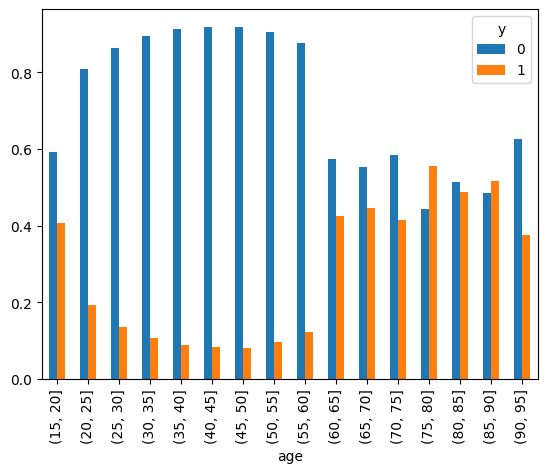

In [41]:
age_bins_fine = pd.cut(data['age'], bins=range(15, 100, 5))
data.groupby(age_bins_fine)['y'].value_counts(normalize=True).unstack().plot(kind='bar')

In [42]:
data['contact'] = data['contact'].map({'telephone': 0, 'cellular': 1})
data['housing'] = data['housing'].replace('unknown', 'no').map({'no': 0, 'yes': 1})
data['loan'] = data['loan'].replace('unknown', 'no').map({'no': 0, 'yes': 1})

In [43]:
data['default'] = data['default'].replace('yes', 'unknown')
data['default'] = data['default'].map({'no': 0, 'unknown': 1})

In [44]:
data['days_since_last_contact'] = data['pdays'].replace(999, np.nan)
data = data.drop(columns=['pdays'])
data['days_since_last_contact'] = data['days_since_last_contact'].fillna(-1)

In [45]:
data['had_previous_contact'] = (data['previous'] > 0).astype(int)

In [46]:
data.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,age_group,days_since_last_contact,had_previous_contact
0,56,housemaid,married,basic.4y,0,0,0,0,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,55-65,-1.0,0
1,57,services,married,high.school,1,0,0,0,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,55-65,-1.0,0
2,37,services,married,high.school,0,1,0,0,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,35-45,-1.0,0
3,40,admin.,married,basic.6y,0,0,0,0,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,35-45,-1.0,0
4,56,services,married,high.school,0,0,1,0,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,55-65,-1.0,0


In [47]:
print(data['month'].unique())

['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'mar' 'apr' 'sep']


<Axes: >

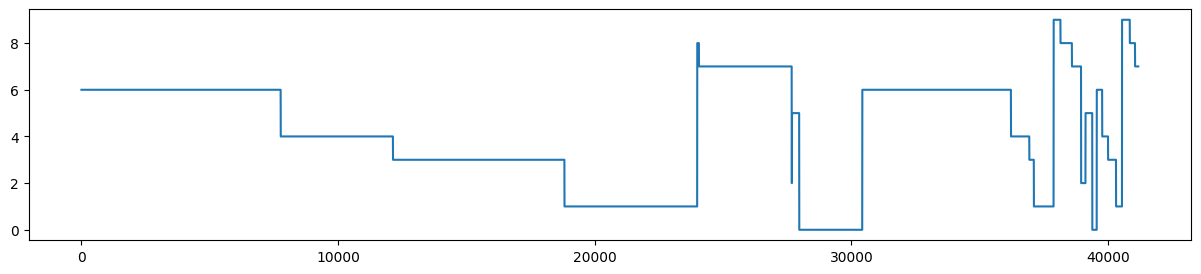

In [48]:
month_sequence = data['month'].astype('category').cat.codes
month_sequence.plot(figsize=(15,3))

Дані впорядковані хронологічно (з травня 2008 по листопад 2010).

In [49]:
split_idx = int(len(data) * 0.8)

df_train = data.iloc[:split_idx].copy()
df_test = data.iloc[split_idx:].copy()

print(f"Train: {df_train.shape}, Test: {df_test.shape}")

Train: (32940, 22), Test: (8236, 22)


## Logistic regression

In [50]:
X_train_logreg = df_train.drop(columns=['y', 'age', 'cons.conf.idx', 'euribor3m', 'emp.var.rate'])
y_train = df_train['y']

X_test_logreg = df_test.drop(columns=['y', 'age', 'cons.conf.idx', 'euribor3m', 'emp.var.rate'])
y_test = df_test['y']

In [51]:
categorical_cols = ['job', 'marital', 'education', 'month', 'day_of_week', 'poutcome']

numeric_cols_logreg = ['campaign', 'days_since_last_contact', 'previous','nr.employed',]

binary_cols = ['default', 'housing', 'loan', 'contact']

preprocessor_logreg = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols_logreg),
    ('cat_nominal', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols),
    ('cat_age_group', OneHotEncoder(drop='first', handle_unknown='ignore'), ['age_group']),
    ('binary', 'passthrough', binary_cols)
])

In [52]:
pipeline_logreg = Pipeline([
    ('preprocessor', preprocessor_logreg),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, ))
])

pipeline_logreg.fit(X_train_logreg, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['campaign',
                                                   'days_since_last_contact',
                                                   'previous', 'nr.employed']),
                                                 ('cat_nominal',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['job', 'marital',
                                                   'education', 'month',
                                                   'day_of_week', 'poutcome']),
                                                 ('cat_age_group',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['age_group']),
                                                 ('binary', 'passthrough',
                                                  ['default', 'housing', 'loan',
                                                   'contact'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [53]:
results = []
def evaluate(name, model, X_tr=None, y_tr=None, X_ts=None, y_ts=None):
    p_train = model.predict_proba(X_tr)[:, 1]
    p_test = model.predict_proba(X_ts)[:, 1]
    row = {'model': name,
           'train_auc': roc_auc_score(y_tr, p_train),
           'test_auc': roc_auc_score(y_ts, p_test),
           'train_pr_auc': average_precision_score(y_tr, p_train),
           'test_pr_auc': average_precision_score(y_ts, p_test)}
    results.append(row)
    print(f"{name}: Train AUC {row['train_auc']:.4f} | Test AUC {row['test_auc']:.4f} | Train PR-AUC {row['train_pr_auc']:.4f} | Test PR-AUC {row['test_pr_auc']:.4f}")

In [54]:
evaluate('Logreg', pipeline_logreg, X_train_logreg, y_train, X_test_logreg, y_test)

Logreg: Train AUC 0.6856 | Test AUC 0.7481 | Train PR-AUC 0.2070 | Test PR-AUC 0.5187


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


## kNN

### kNN(base)

In [55]:
X_train_other = df_train.drop(columns=['y', 'age_group', 'cons.conf.idx', 'euribor3m', 'emp.var.rate'])
y_train = df_train['y']

X_test_other = df_test.drop(columns=['y', 'age_group', 'cons.conf.idx', 'euribor3m', 'emp.var.rate'])
y_test = df_test['y']

In [56]:
categorical_cols = ['job', 'marital', 'education', 'month', 'day_of_week', 'poutcome']

numeric_cols_knn = ['campaign', 'days_since_last_contact', 'previous', 'nr.employed', 'age']

binary_cols = ['default', 'housing', 'loan', 'contact']

In [57]:
preprocessor_knn = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols_knn),
    ('cat_nominal', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols),
    ('binary', 'passthrough', binary_cols)
])

pipeline_knn = Pipeline([
    ('preprocessor', preprocessor_knn),
    ('knn_classifier', KNeighborsClassifier())
])

pipeline_knn.fit(X_train_other, y_train)

evaluate('kNN base', pipeline_knn, X_train_other, y_train, X_test_other, y_test)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


kNN base: Train AUC 0.9244 | Test AUC 0.6379 | Train PR-AUC 0.3693 | Test PR-AUC 0.4182


### kNN(n_neighbors=150)

In [58]:
pipeline_knn_150 = Pipeline([
    ('preprocessor', preprocessor_knn),
    ('knn_classifier', KNeighborsClassifier(n_neighbors=150))
])

pipeline_knn_150.fit(X_train_other, y_train)

evaluate('kNN 150', pipeline_knn_150, X_train_other, y_train, X_test_other, y_test)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


kNN 150: Train AUC 0.7089 | Test AUC 0.7151 | Train PR-AUC 0.1901 | Test PR-AUC 0.5119


### kNN(Undersampling)

In [59]:
pipeline_knn_under = ImbPipeline([
    ('preprocessor', preprocessor_knn),
    ('undersample', RandomUnderSampler(random_state=42)),
    ('knn_classifier', KNeighborsClassifier())
])

pipeline_knn_under.fit(X_train_other, y_train)

evaluate('kNN Undersampling', pipeline_knn_under, X_train_other, y_train, X_test_other, y_test)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


kNN Undersampling: Train AUC 0.7263 | Test AUC 0.6574 | Train PR-AUC 0.1502 | Test PR-AUC 0.4151


## Decision Tree

In [60]:
categorical_cols = ['job', 'marital', 'education', 'month', 'day_of_week', 'poutcome']

numeric_cols_tree = ['age', 'campaign', 'days_since_last_contact', 'previous', 'nr.employed']

binary_cols = ['default', 'housing', 'loan', 'contact', 'had_previous_contact']

preprocessor_tree = ColumnTransformer([
    ('num', 'passthrough', numeric_cols_tree),
    ('cat_nominal', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols),
    ('binary', 'passthrough', binary_cols)
])

pipeline_tree = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('tree_classifier', DecisionTreeClassifier(class_weight='balanced', random_state=42))
])

pipeline_tree.fit(X_train_other, y_train)

evaluate('Decision Tree (base)', pipeline_tree, X_train_other, y_train, X_test_other, y_test)

Decision Tree (base): Train AUC 0.9996 | Test AUC 0.5342 | Train PR-AUC 0.9907 | Test PR-AUC 0.3268


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [61]:
print(pipeline_tree.named_steps['tree_classifier'].get_depth())

43


In [62]:
pipeline_tree_limited = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('tree_classifier', DecisionTreeClassifier(
        class_weight='balanced',
        max_depth=10,
        min_samples_leaf=50,
        random_state=42
    ))
])

pipeline_tree_limited.fit(X_train_other, y_train)

evaluate('Decision Tree (max_depth=10, min_samples_leaf=50)', pipeline_tree_limited, X_train_other, y_train, X_test_other, y_test)

Decision Tree (max_depth=10, min_samples_leaf=50): Train AUC 0.7378 | Test AUC 0.6721 | Train PR-AUC 0.2320 | Test PR-AUC 0.4446


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


## Boosting Algorithms

In [63]:
print(X_train_other.columns.tolist())
print(X_train_other.shape, X_test_other.shape)

['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'previous', 'poutcome', 'cons.price.idx', 'nr.employed', 'days_since_last_contact', 'had_previous_contact']
(32940, 17) (8236, 17)


### XGB(base)

In [64]:
preprocessor_xgb = ColumnTransformer([
    ('num', 'passthrough', numeric_cols_tree),
    ('cat_nominal', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols),
    ('binary', 'passthrough', binary_cols)
])

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

pipeline_xgb = Pipeline([
    ('preprocessor', preprocessor_xgb),
    ('xgb_classifier', XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        eval_metric='auc',
        random_state=42
    ))
])

pipeline_xgb.fit(X_train_other, y_train)

evaluate('XGB', pipeline_xgb, X_train_other, y_train, X_test_other, y_test)

scale_pos_weight: 14.69
XGB: Train AUC 0.9171 | Test AUC 0.6200 | Train PR-AUC 0.5144 | Test PR-AUC 0.4232


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


### XGB(RandomizedSearchCV)

In [65]:
tscv = TimeSeriesSplit(n_splits=5)

param_dist = {
    'xgb_classifier__n_estimators': [100, 200, 300, 500],
    'xgb_classifier__max_depth': [3, 4, 5, 6, 8],
    'xgb_classifier__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'xgb_classifier__subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'xgb_classifier__colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'xgb_classifier__min_child_weight': [1, 3, 5, 7],
    'xgb_classifier__gamma': [0, 0.1, 0.3, 0.5]
}

random_search = RandomizedSearchCV(
    pipeline_xgb,
    param_distributions=param_dist,
    n_iter=50,
    cv=tscv,
    scoring='average_precision',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train_other, y_train)

print("Best params:", random_search.best_params_)
print("Best score:", random_search.best_score_)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best params: {'xgb_classifier__subsample': 1.0, 'xgb_classifier__n_estimators': 200, 'xgb_classifier__min_child_weight': 3, 'xgb_classifier__max_depth': 5, 'xgb_classifier__learning_rate': 0.01, 'xgb_classifier__gamma': 0, 'xgb_classifier__colsample_bytree': 0.6}
Best score: 0.0818862555882722


In [66]:
best_xgb_random = random_search.best_estimator_

evaluate('XGB (RandomizedSearchCV)', best_xgb_random, X_train_other, y_train, X_test_other, y_test)

XGB (RandomizedSearchCV): Train AUC 0.7144 | Test AUC 0.7431 | Train PR-AUC 0.2464 | Test PR-AUC 0.5358


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


### XGB(Hyperopt)

In [67]:
preprocessor_xgb = ColumnTransformer([
    ('num', 'passthrough', numeric_cols_tree),
    ('cat_nominal', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols),
    ('binary', 'passthrough', binary_cols)
])

X_train_transformed = preprocessor_xgb.fit_transform(X_train_other, y_train)
X_test_transformed = preprocessor_xgb.transform(X_test_other)

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

def objective(params):
    clf = xgb.XGBClassifier(
        n_estimators=int(params['n_estimators']),
        learning_rate=params['learning_rate'],
        max_depth=int(params['max_depth']),
        min_child_weight=params['min_child_weight'],
        subsample=params['subsample'],
        colsample_bytree=params['colsample_bytree'],
        gamma=params['gamma'],
        reg_alpha=params['reg_alpha'],
        reg_lambda=params['reg_lambda'],
        missing=np.nan,
        device='cuda',
        early_stopping_rounds=10,
        eval_metric='auc',
        scale_pos_weight=scale_pos_weight
    )

    clf.fit(
        X_train_transformed,
        y_train,
        eval_set=[(X_test_transformed, y_test)],
        verbose=False)

    probs = clf.predict_proba(X_test_transformed)[:, 1]
    auc = roc_auc_score(y_test, probs)

    return {'loss': -auc, 'status': STATUS_OK}


space = {
    'n_estimators': hp.quniform('n_estimators', 50, 500, 25),
    'learning_rate': hp.uniform('learning_rate', 0.01, 0.3),
    'max_depth': hp.quniform('max_depth', 3, 15, 1),
    'min_child_weight': hp.quniform('min_child_weight', 1, 10, 1),
    'subsample': hp.uniform('subsample', 0.5, 1.0),
    'colsample_bytree': hp.uniform('colsample_bytree', 0.5, 1.0),
    'gamma': hp.uniform('gamma', 0, 0.5),
    'reg_alpha': hp.uniform('reg_alpha', 0, 1),
    'reg_lambda': hp.uniform('reg_lambda', 0, 1)
}

trials = Trials()
best = fmin(fn=objective, space=space, algo=tpe.suggest, max_evals=20, trials=trials)

best['n_estimators'] = int(best['n_estimators'])
best['max_depth'] = int(best['max_depth'])
best['min_child_weight'] = int(best['min_child_weight'])

print("Найкращі гіперпараметри: ", best)

final_pipeline_xgb = Pipeline([
    ('preprocessor', preprocessor_xgb),
    ('xgb_classifier', xgb.XGBClassifier(
        n_estimators=best['n_estimators'],
        learning_rate=best['learning_rate'],
        max_depth=best['max_depth'],
        min_child_weight=best['min_child_weight'],
        subsample=best['subsample'],
        colsample_bytree=best['colsample_bytree'],
        gamma=best['gamma'],
        reg_alpha=best['reg_alpha'],
        reg_lambda=best['reg_lambda'],
        missing=np.nan,
        device='cuda'
    ))
])

final_pipeline_xgb.fit(X_train_other, y_train)

evaluate('XGB (Hyperopt)', final_pipeline_xgb, X_train_other, y_train, X_test_other, y_test)

  0%|          | 0/20 [00:00<?, ?trial/s, best loss=?]

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/xgboost/callback.py:385: UserWarning: [19:18:04] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  self.starting_round = model.num_boosted_rounds()

/usr/local/lib/python3.13/dist-packages/xgboost/callback.py:385: UserWarning: [19:18:04] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  self.starting_round = model.num_boosted_rounds()



  5%|▌         | 1/20 [00:00<00:04,  3.92trial/s, best loss: -0.7402815879200394]

/usr/local/lib/python3.13/dist-packages/xgboost/callback.py:385: UserWarning: [19:18:04] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  self.starting_round = model.num_boosted_rounds()

/usr/local/lib/python3.13/dist-packages/xgboost/callback.py:385: UserWarning: [19:18:04] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  self.starting_round = model.num_boosted_rounds()



 15%|█▌        | 3/20 [00:00<00:05,  3.15trial/s, best loss: -0.7431723875317557]

...

/usr/local/lib/python3.13/dist-packages/xgboost/callback.py:385: UserWarning: [19:18:11] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  self.starting_round = model.num_boosted_rounds()

/usr/local/lib/python3.13/dist-packages/xgboost/callback.py:385: UserWarning: [19:18:11] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  self.starting_round = model.num_boosted_rounds()



100%|██████████| 20/20 [00:07<00:00,  2.64trial/s, best loss: -0.752538717924202]
Найкращі гіперпараметри:  {'colsample_bytree': np.float64(0.7351093273434057), 'gamma': np.float64(0.3728681425390954), 'learning_rate': np.float64(0.030058130888955877), 'max_depth': 4, 'min_child_weight': 4, 'n_estimators': 125, 'reg_alpha': np.float64(0.0708730266736336), 'reg_lambda': np.float64(0.7309796888757651), 'subsample': np.float64(0.8852441782776701)}


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [19:18:11] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [19:18:11] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


XGB (Hyperopt): Train AUC 0.7088 | Test AUC 0.7352 | Train PR-AUC 0.2350 | Test PR-AUC 0.5055


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


### LGBM(RandomizedSearchCV)

In [68]:
preprocessor_lgbm = ColumnTransformer([
    ('num', 'passthrough', numeric_cols_tree),
    ('cat_nominal', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols),
    ('binary', 'passthrough', binary_cols)
])

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

In [69]:
tscv = TimeSeriesSplit(n_splits=5)

pipeline_lgbm = Pipeline([
    ('preprocessor', preprocessor_lgbm),
    ('lgbm_classifier', lgb.LGBMClassifier(
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        verbose=-1
    ))
])

param_dist = {
    'lgbm_classifier__n_estimators': randint(50, 500),
    'lgbm_classifier__max_depth': randint(3, 15),
    'lgbm_classifier__learning_rate': uniform(0.01, 0.29),
    'lgbm_classifier__num_leaves': randint(15, 150),
    'lgbm_classifier__subsample': uniform(0.5, 0.5),
    'lgbm_classifier__colsample_bytree': uniform(0.5, 0.5),
    'lgbm_classifier__min_child_samples': randint(5, 100),
    'lgbm_classifier__reg_alpha': uniform(0, 1),
    'lgbm_classifier__reg_lambda': uniform(0, 1)
}

random_search_lgbm = RandomizedSearchCV(
    pipeline_lgbm,
    param_distributions=param_dist,
    n_iter=50,
    cv=tscv,
    scoring='average_precision',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search_lgbm.fit(X_train_other, y_train)

print("Best params:", random_search_lgbm.best_params_)
print("Best score:", random_search_lgbm.best_score_)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best params: {'lgbm_classifier__colsample_bytree': np.float64(0.8480148983374864), 'lgbm_classifier__learning_rate': np.float64(0.17531773932591585), 'lgbm_classifier__max_depth': 10, 'lgbm_classifier__min_child_samples': 36, 'lgbm_classifier__n_estimators': 480, 'lgbm_classifier__num_leaves': 100, 'lgbm_classifier__reg_alpha': np.float64(0.3586467812961639), 'lgbm_classifier__reg_lambda': np.float64(0.25416364906973876), 'lgbm_classifier__subsample': np.float64(0.6476452942094694)}
Best score: 0.07628155561142266


In [70]:
best_lgbm_random = random_search_lgbm.best_estimator_

evaluate('LGBM (Randomized Search)', best_lgbm_random, X_train_other, y_train, X_test_other, y_test)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LGBM (Randomized Search): Train AUC 0.9935 | Test AUC 0.6579 | Train PR-AUC 0.8822 | Test PR-AUC 0.4327


### LGBM(Hyperopt)

In [71]:
X_train_transformed = preprocessor_lgbm.fit_transform(X_train_other, y_train)
X_test_transformed = preprocessor_lgbm.transform(X_test_other)

def objective_lgbm(params):
    clf = lgb.LGBMClassifier(
        n_estimators=int(params['n_estimators']),
        max_depth=int(params['max_depth']),
        learning_rate=params['learning_rate'],
        num_leaves=int(params['num_leaves']),
        subsample=params['subsample'],
        colsample_bytree=params['colsample_bytree'],
        min_child_samples=int(params['min_child_samples']),
        reg_alpha=params['reg_alpha'],
        reg_lambda=params['reg_lambda'],
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        verbose=-1
    )

    clf.fit(
        X_train_transformed,
        y_train,
        eval_set=[(X_test_transformed, y_test)],
        callbacks=[lgb.early_stopping(stopping_rounds=10, verbose=False)]
    )

    probs = clf.predict_proba(X_test_transformed)[:, 1]
    auc = roc_auc_score(y_test, probs)

    return {'loss': -auc, 'status': STATUS_OK}


space_lgbm = {
    'n_estimators': hp.quniform('n_estimators', 50, 500, 25),
    'max_depth': hp.quniform('max_depth', 3, 15, 1),
    'learning_rate': hp.uniform('learning_rate', 0.01, 0.3),
    'num_leaves': hp.quniform('num_leaves', 15, 150, 5),
    'subsample': hp.uniform('subsample', 0.5, 1.0),
    'colsample_bytree': hp.uniform('colsample_bytree', 0.5, 1.0),
    'min_child_samples': hp.quniform('min_child_samples', 5, 100, 5),
    'reg_alpha': hp.uniform('reg_alpha', 0, 1),
    'reg_lambda': hp.uniform('reg_lambda', 0, 1)
}

trials_lgbm = Trials()
best_lgbm = fmin(
    fn=objective_lgbm,
    space=space_lgbm,
    algo=tpe.suggest,
    max_evals=20,
    trials=trials_lgbm
)

best_lgbm['n_estimators'] = int(best_lgbm['n_estimators'])
best_lgbm['max_depth'] = int(best_lgbm['max_depth'])
best_lgbm['num_leaves'] = int(best_lgbm['num_leaves'])
best_lgbm['min_child_samples'] = int(best_lgbm['min_child_samples'])

print("Найкращі гіперпараметри: ", best_lgbm)

final_pipeline_lgbm = Pipeline([
    ('preprocessor', preprocessor_lgbm),
    ('lgbm_classifier', lgb.LGBMClassifier(
        n_estimators=best_lgbm['n_estimators'],
        max_depth=best_lgbm['max_depth'],
        learning_rate=best_lgbm['learning_rate'],
        num_leaves=best_lgbm['num_leaves'],
        subsample=best_lgbm['subsample'],
        colsample_bytree=best_lgbm['colsample_bytree'],
        min_child_samples=best_lgbm['min_child_samples'],
        reg_alpha=best_lgbm['reg_alpha'],
        reg_lambda=best_lgbm['reg_lambda'],
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        verbose=-1
    ))
])

final_pipeline_lgbm.fit(X_train_other, y_train)

evaluate('LGBM (Hyperopt)', final_pipeline_lgbm, X_train_other, y_train, X_test_other, y_test)

  0%|          | 0/20 [00:00<?, ?trial/s, best loss=?]

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


  5%|▌         | 1/20 [00:00<00:07,  2.65trial/s, best loss: -0.7419616454781622]

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



 15%|█▌        | 3/20 [00:00<00:03,  4.61trial/s, best loss: -0.7419616454781622]

...

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



100%|██████████| 20/20 [00:03<00:00,  5.48trial/s, best loss: -0.7419616454781622]
Найкращі гіперпараметри:  {'colsample_bytree': np.float64(0.6120681927211082), 'learning_rate': np.float64(0.018839336157885075), 'max_depth': 6, 'min_child_samples': 85, 'n_estimators': 300, 'num_leaves': 95, 'reg_alpha': np.float64(0.40304581349656254), 'reg_lambda': np.float64(0.01706148252071804), 'subsample': np.float64(0.8525685459425143)}


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LGBM (Hyperopt): Train AUC 0.7673 | Test AUC 0.7443 | Train PR-AUC 0.2514 | Test PR-AUC 0.5710


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


## Voting

In [72]:
log_reg = pipeline_logreg
xgb_hyp = final_pipeline_xgb
knn_150 = pipeline_knn_150

X_train_full = df_train.drop(columns=['y'])
X_test_full = df_test.drop(columns=['y'])

estimators=[('log_reg', log_reg), ('xgb_hyp', xgb_hyp), ('knn_150', knn_150)]

ensemble_voting = VotingClassifier(estimators, voting='soft')

ensemble_voting.fit(X_train_full, y_train)

evaluate('Voting', ensemble_voting, X_train_full, y_train, X_test_full, y_test)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [19:21:06] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [19:21:06] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preproce

Voting: Train AUC 0.6984 | Test AUC 0.7489 | Train PR-AUC 0.2194 | Test PR-AUC 0.5312


## Аналіз моделей

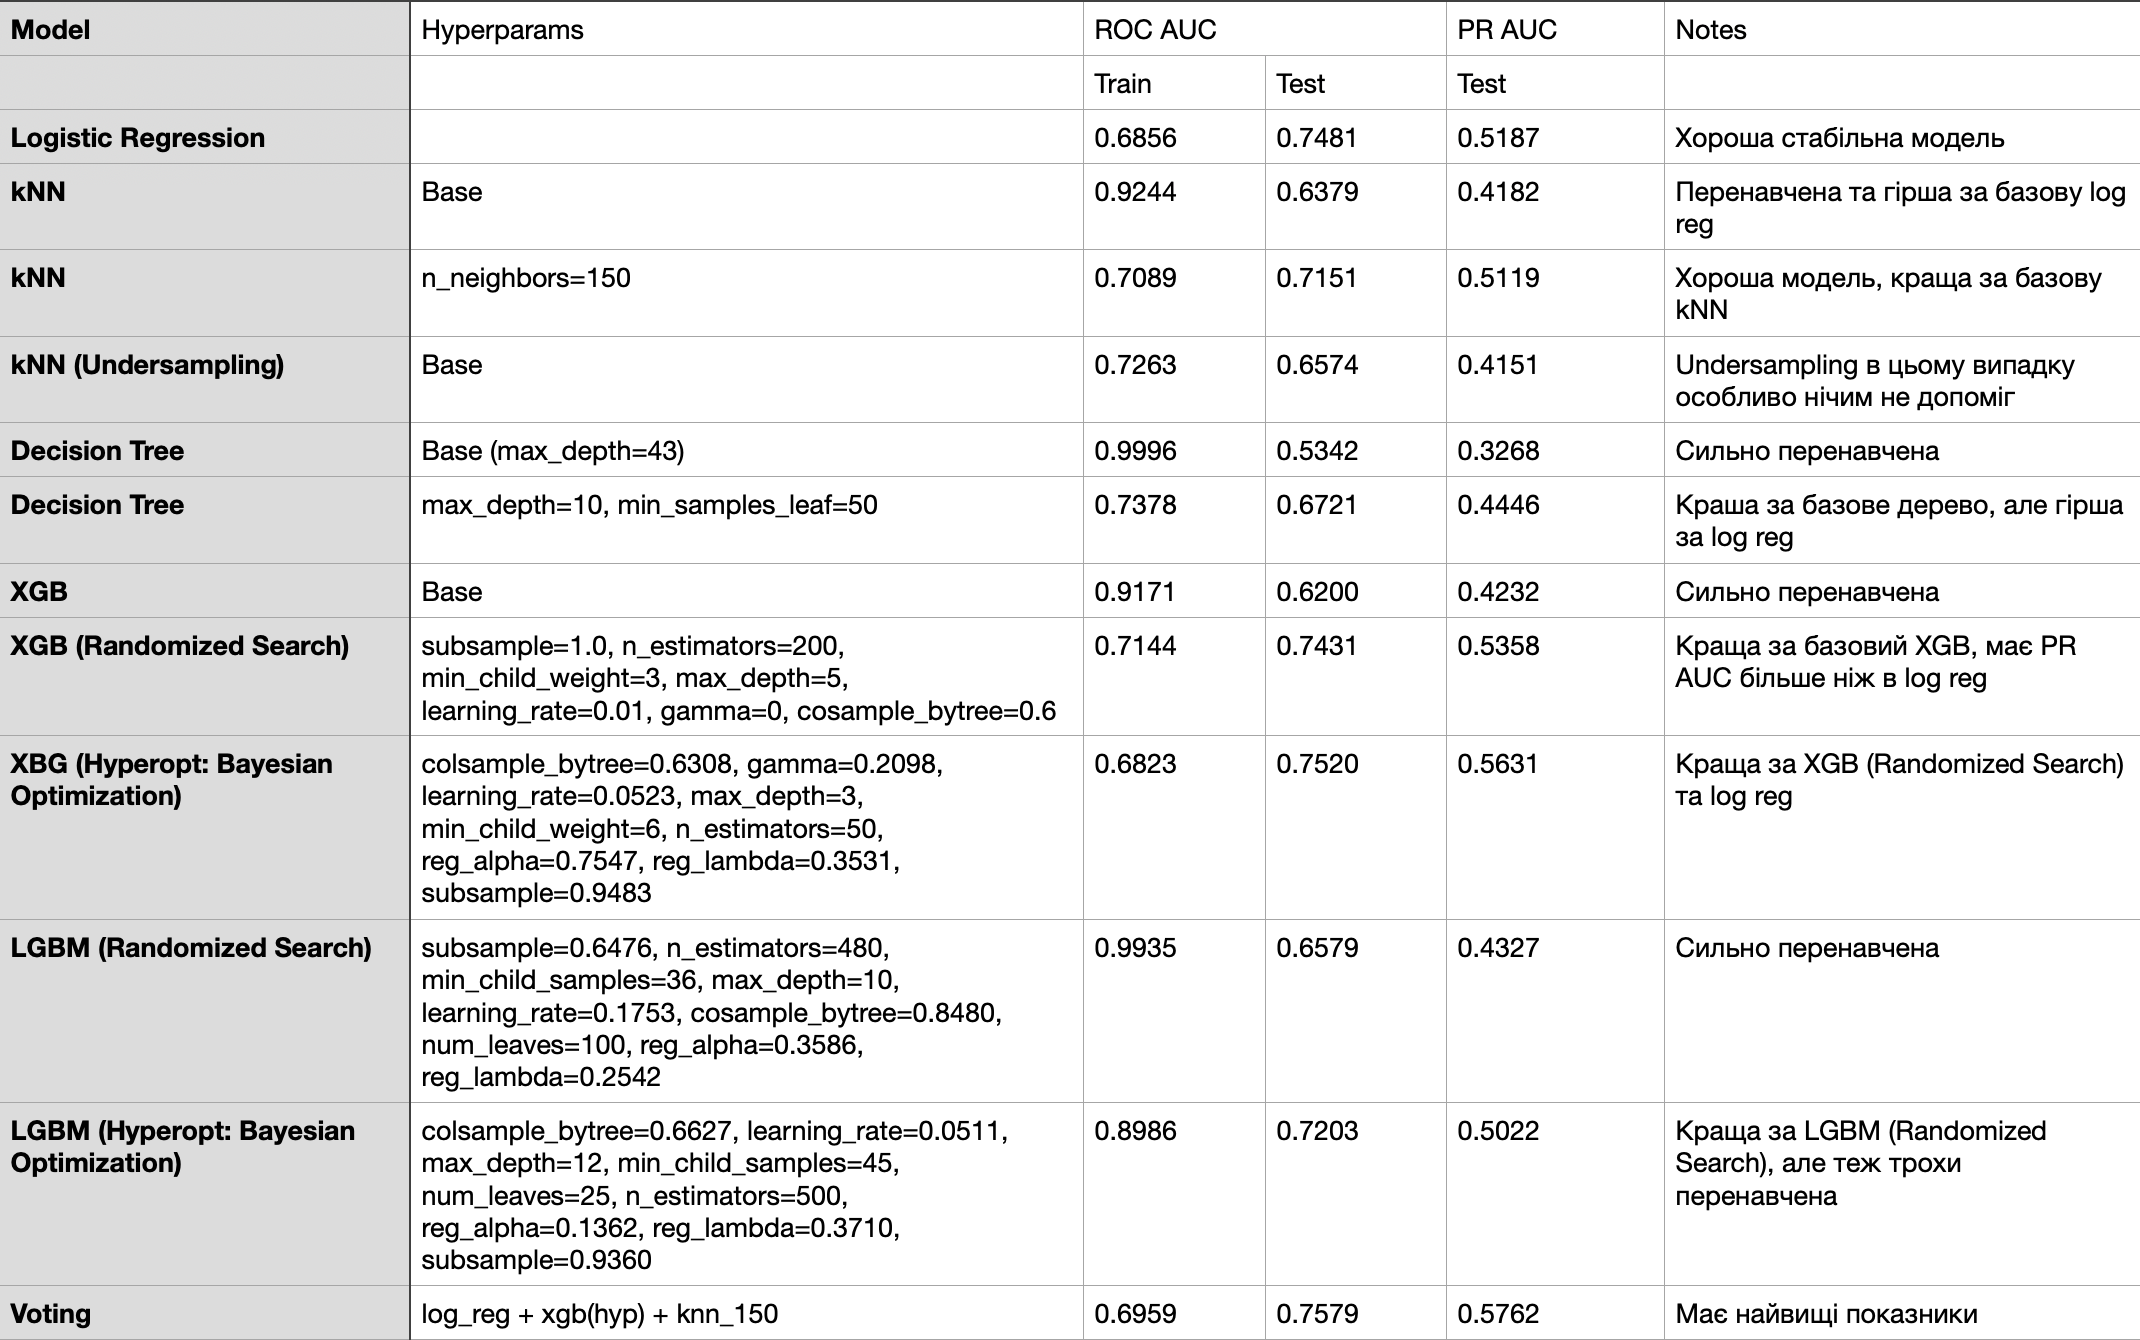

**Висновки по результатах моделей**

Найнадійніші результати показують Logistic Regression (0.748/PR AUC 0.5187) і XGB з RandomizedSearchCV (0.743/PR AUC 0.5358): вони не перенавчені і достатньо сильні.

Між цими двома моделями вважаю доречним обрати більш просту Logistic Regression.

### Важливість ознак моделі

In [73]:
prep = pipeline_logreg.named_steps["preprocessor"]
clf = pipeline_logreg.named_steps["classifier"]
feat_names = prep.get_feature_names_out()
coef = clf.coef_.ravel()
imp = (pd.DataFrame({"feature": feat_names, "coef": coef})
         .assign(abs_coef=lambda d: d["coef"].abs())
         .sort_values("abs_coef", ascending=False))

imp.head(10)

,feature,coef,abs_coef
32,cat_nominal__month_oct,2.931071,2.931071
38,cat_nominal__poutcome_success,1.800057,1.800057
29,cat_nominal__month_mar,1.216326,1.216326
30,cat_nominal__month_may,-0.872437,0.872437
42,cat_age_group__age_group_65+,0.710225,0.710225
37,cat_nominal__poutcome_nonexistent,0.706454,0.706454
31,cat_nominal__month_nov,-0.532572,0.532572
11,cat_nominal__job_student,0.511289,0.511289
17,cat_nominal__marital_unknown,0.425493,0.425493
21,cat_nominal__education_illiterate,0.414990,0.414990


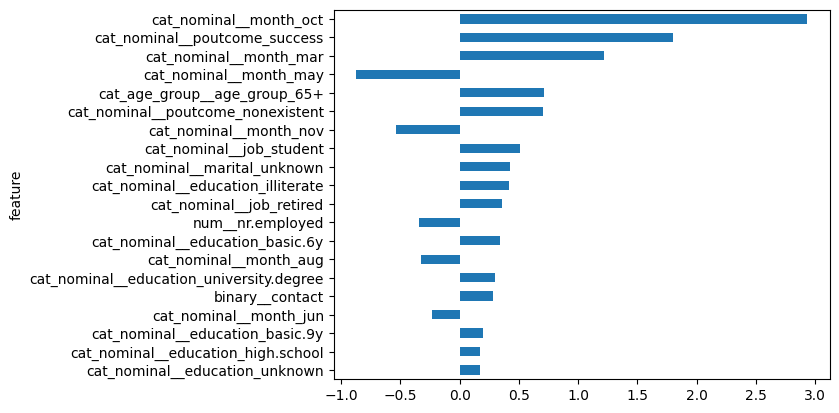

In [74]:
ax = imp.head(20).sort_values("abs_coef").plot.barh(x="feature", y="coef", legend=False)

**Висновки**

В цілому цей пріоритет важливості ознак є адекватним з точки зору common sense в цьому випадку, але є кілька ознак, до яких є питання.

Ознаки місяців oct, mar, may, nov входят в топ важливих в цьому проекті, що є цілком зрозумілим, адже в цьому випадку вони більше вказують на якийсь період в хронології даних, ніж на сезонність. Бо дані зібрані і в період кризи, і післякризовий період, не всі місяці повторюються в обох періодах.

`poutcome = success` - теж одна з найважливіших ознак. Ще на етапі EDA було помічено, що успіх попередніх компаній сильно впливав на успіх в підписанні депозиту.

Клієнти похилого віку більше підписують депозити - підтвердження однієї з гіпотез по результатах EDA.

`poutcome = nonexistent` представлена, як ознака, що має позитивний вплив, що викликає сумніви, адже на етапі EDA визначено, що навіть `poutcome = failure` має більший відсоток підписань. Тому на мою думку більше сенсу мав би негативний вплив ціє ознаки.




### Аналіз впливу ознак (SHAP)

In [75]:
cols   = X_train_logreg.columns
dtypes = X_train_logreg.dtypes.to_dict()

def predict_fn(x):
    df = pd.DataFrame(x, columns=cols).astype(dtypes)
    return pipeline_logreg.predict_proba(df)[:, 1]

background = shap.sample(X_train_logreg, 200, random_state=42)

explainer = shap.KernelExplainer(predict_fn, background)

X_explain = X_test_logreg[cols].sample(100, random_state=42)
shap_values = explainer.shap_values(X_explain, nsamples=500)

  0%|          | 0/100 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

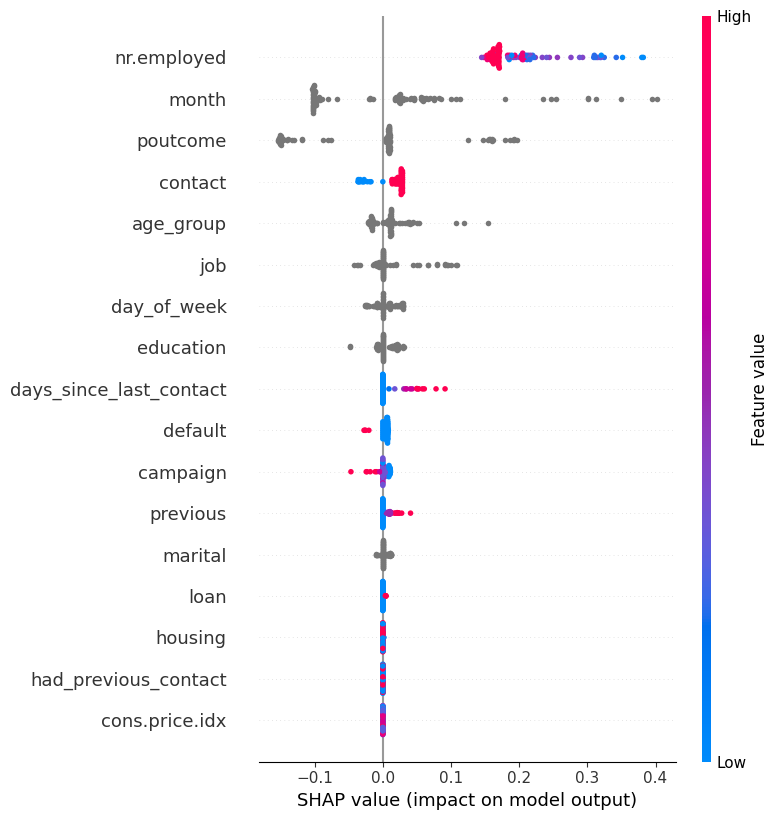

In [76]:
shap.summary_plot(shap_values, X_explain)

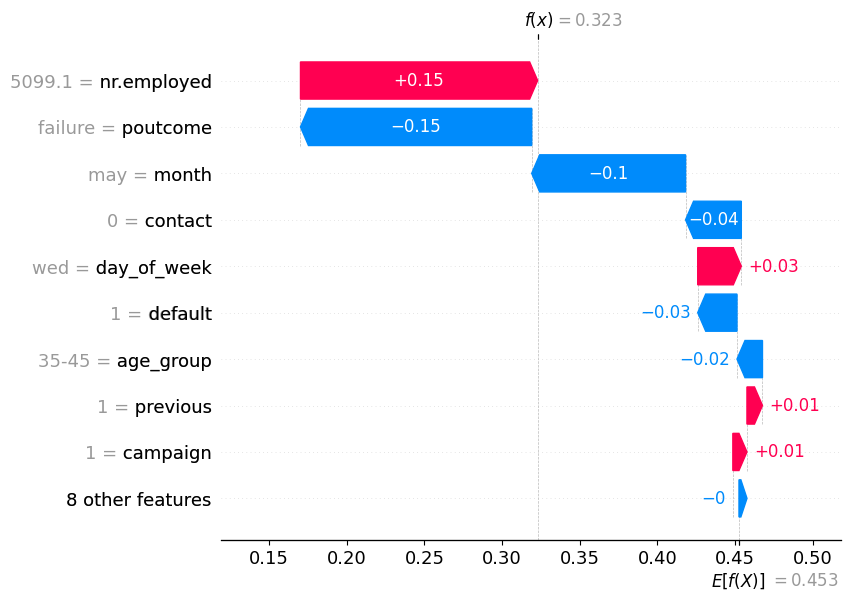

In [77]:
i = 0
exp = shap.Explanation(
    values=shap_values[i],
    base_values=explainer.expected_value,
    data=X_explain.iloc[i].values,
    feature_names=list(cols),
)
shap.plots.waterfall(exp)

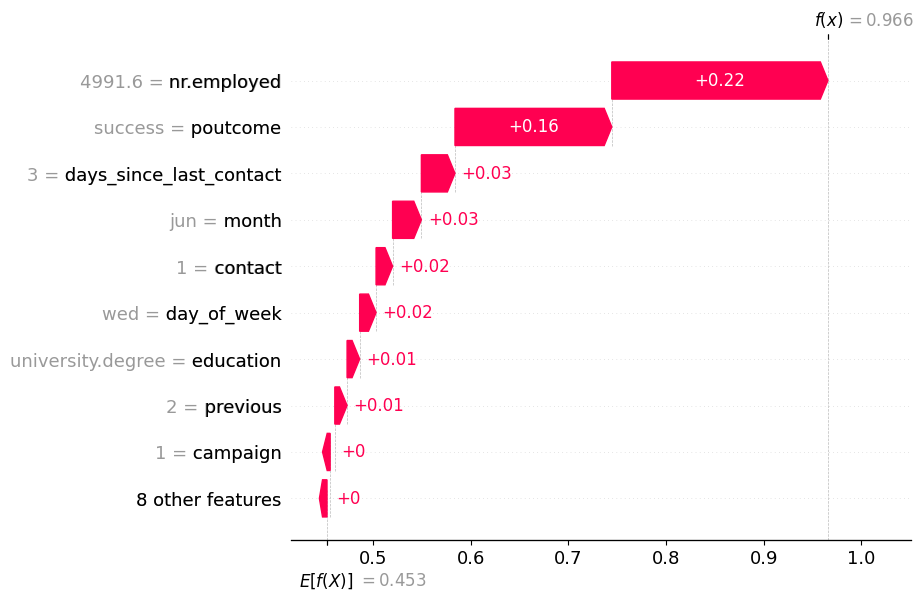

In [78]:
i = 3
exp = shap.Explanation(
    values=shap_values[i],
    base_values=explainer.expected_value,
    data=X_explain.iloc[i].values,
    feature_names=list(cols),
)
shap.plots.waterfall(exp)

**Висновки**

На графіках, виведених за допомогою бібліотеки SHAP все виглядає цілком логічно.

### Аналіз помилок

In [79]:
pos, neg = pipeline_logreg.classes_[1], pipeline_logreg.classes_[0]
proba_pos = pipeline_logreg.predict_proba(X_test_logreg)[:, 1]
thr = 0.8
y_pred = np.where(proba_pos >= thr, pos, neg)

df = X_test_logreg.copy()
df["y_true"] = y_test.values
df["proba_pos"] = proba_pos
df["y_pred"] = y_pred

fp = df[(df.y_true == neg) & (df.y_pred == pos)].sort_values("proba_pos", ascending=False)
fn = df[(df.y_true == pos) & (df.y_pred == neg)].sort_values("proba_pos", ascending=True)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [80]:
confusion_matrix(y_test.values, y_pred)

array([[4077, 1620],
       [ 878, 1661]])

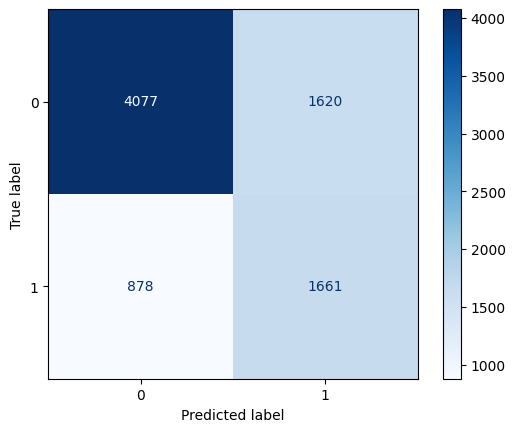

In [81]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['0', '1']).plot(cmap='Blues')
plt.show()

In [82]:
print(classification_report(y_test.values, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.72      0.77      5697
           1       0.51      0.65      0.57      2539

    accuracy                           0.70      8236
   macro avg       0.66      0.68      0.67      8236
weighted avg       0.73      0.70      0.71      8236



In [83]:
fp

,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,previous,poutcome,cons.price.idx,nr.employed,age_group,days_since_last_contact,had_previous_contact,y_true,proba_pos,y_pred
40845,technician,unknown,university.degree,0,0,0,1,oct,fri,2,1,success,94.601,4963.6,25-35,16.0,1,0,0.999612,1
40954,retired,married,university.degree,0,1,0,1,oct,fri,2,2,success,94.601,4963.6,65+,3.0,1,0,0.999556,1
40873,admin.,single,university.degree,0,0,0,1,oct,thu,1,1,success,94.601,4963.6,25-35,17.0,1,0,0.999534,1
41019,student,single,high.school,0,1,0,1,oct,mon,1,4,success,94.601,4963.6,<25,6.0,1,0,0.999453,1
40938,retired,divorced,basic.4y,0,1,0,1,oct,thu,2,2,success,94.601,4963.6,65+,3.0,1,0,0.999423,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38733,technician,married,university.degree,0,1,0,1,nov,wed,1,0,nonexistent,92.649,5017.5,35-45,-1.0,0,0,0.800517,1
37440,self-employed,single,university.degree,0,0,0,1,aug,wed,1,0,nonexistent,92.201,5076.2,25-35,-1.0,0,0,0.800390,1
36565,management,divorced,university.degree,0,1,0,1,jun,wed,1,0,nonexistent,92.963,5076.2,25-35,-1.0,0,0,0.800365,1
39750,retired,married,professional.course,0,0,0,1,may,fri,4,3,failure,93.876,5008.7,65+,-1.0,1,0,0.800263,1


In [84]:
fn

,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,previous,poutcome,cons.price.idx,nr.employed,age_group,days_since_last_contact,had_previous_contact,y_true,proba_pos,y_pred
35969,blue-collar,married,basic.4y,0,0,0,1,may,mon,3,1,failure,92.893,5099.1,45-55,-1.0,1,1,0.304682,0
35633,unemployed,married,basic.4y,0,0,0,1,may,mon,1,1,failure,92.893,5099.1,25-35,-1.0,1,1,0.318533,0
33168,blue-collar,married,basic.4y,1,0,0,1,may,tue,1,1,failure,92.893,5099.1,25-35,-1.0,1,1,0.334283,0
33332,blue-collar,married,basic.4y,0,1,0,1,may,tue,1,1,failure,92.893,5099.1,35-45,-1.0,1,1,0.336112,0
33310,blue-collar,married,high.school,0,1,0,1,may,tue,10,1,failure,92.893,5099.1,25-35,-1.0,1,1,0.341162,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37751,retired,married,unknown,0,0,0,1,aug,fri,4,0,nonexistent,92.201,5076.2,55-65,-1.0,0,1,0.799783,0
37533,retired,married,unknown,0,0,0,1,aug,fri,4,0,nonexistent,92.201,5076.2,55-65,-1.0,0,1,0.799783,0
41064,blue-collar,divorced,professional.course,0,1,0,1,nov,mon,1,0,nonexistent,94.767,4963.6,45-55,-1.0,0,1,0.799922,0
39518,admin.,married,high.school,0,0,0,0,apr,tue,2,0,nonexistent,93.749,5008.7,35-45,-1.0,0,1,0.799932,0


**Висновки**

Найменше помилок при threshold = 0.8, 1620 FP та 878 FN. При цьому f1-score = 0.77 для класу 0 та f1-score = 0.57 для класу 1.

З великою впевненістю модель каже "так", коли `poutcome = success`, де насправді "ні". І навпаки - каже "ні", коли `poutcome = failure`, де насправді "так".

Те, що ознака `poutcome` має сильний вплив, було видно і при аналізі за допомогою бібліотеки SHAP.

Так само з ознакою `nr.employed`.

При значенні `nr.employed = 5099.1`, тобто максимальному, помиляється і впевненіше каже "так" і навпаки з мінімальним значенням `nr.employed`.

Тобто модель в більшою впевненістю помиляється коли є звʼязка `poutcome = success` + нижчий `nr.employed` (FP) та `poutcome = failure` + вищий `nr.employed` (FN).
